# Session, order and user model

`sql/02_model.sql` builds four tables from the raw events:

| Table | Grain |
|---|---|
| `fact_events` | one row per event, with the session key and first-touch channel |
| `fact_sessions` | one row per `user_pseudo_id` + `ga_session_id` |
| `fact_transactions` | one row per valid, deduplicated `transaction_id` |
| `dim_users` | one row per `user_pseudo_id`, with first-session attributes |

This notebook checks the model reconciles, and sets the date windows in which each funnel event is actually tracked.

In [1]:
import sys
sys.path.insert(0, "scripts")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import analysis as a

pd.set_option("display.float_format", "{:,.4f}".format)
a.chart_style()
con = a.connect()
q = lambda sql: con.sql(sql).df()

## Sessions

A session is `user_pseudo_id` + `ga_session_id`. Published analyses of this sample report 354,970 (the `session_start` event count) or 360,129 (distinct user and session id pairs); this model uses the second, so sessions without a `session_start` event still count.

In [2]:
q("""
SELECT COUNT(*) AS sessions,
       COUNT(*) FILTER (WHERE has_session_start) AS with_session_start,
       COUNT(*) FILTER (WHERE NOT has_session_start) AS without_session_start,
       COUNT(*) FILTER (WHERE is_new_session) AS new_sessions,
       COUNT(DISTINCT user_pseudo_id) AS users
FROM fact_sessions
""")

,sessions,with_session_start,without_session_start,new_sessions,users
0,360129,354857,5272,261238,270154


## Orders

Orders are valid transaction ids with revenue, one row each. Session revenue must equal transaction revenue, and no id may repeat.

In [3]:
checks = q("""
SELECT (SELECT COUNT(*) FROM events_flat WHERE event_name = 'purchase') AS purchase_events,
       (SELECT COUNT(*) FROM fact_transactions) AS orders,
       (SELECT COUNT(DISTINCT transaction_id) FROM fact_transactions) AS distinct_order_ids,
       (SELECT SUM(purchase_revenue_usd) FROM events_flat WHERE event_name = 'purchase') AS raw_purchase_revenue,
       (SELECT SUM(revenue_usd) FROM fact_transactions) AS order_revenue,
       (SELECT SUM(revenue_usd) FROM fact_sessions) AS session_revenue,
       (SELECT SUM(revenue_usd) FROM dim_users) AS user_revenue
""")
assert checks.orders[0] == checks.distinct_order_ids[0]
assert abs(checks.order_revenue[0] - checks.session_revenue[0]) < 0.01
assert abs(checks.order_revenue[0] - checks.user_revenue[0]) < 0.01
checks

,purchase_events,orders,distinct_order_ids,raw_purchase_revenue,order_revenue,session_revenue,user_revenue
0,5692,4451,4451,"362,165.0000","307,640.0000","307,640.0000","307,640.0000"


In [4]:
q("""
SELECT COUNT(*) AS repeat_events, SUM(purchase_revenue_usd) AS repeat_revenue
FROM (SELECT * FROM fact_events
      WHERE event_name = 'purchase' AND transaction_id IS NOT NULL AND trim(transaction_id) <> ''
        AND transaction_id NOT IN ('(not set)', '<Other>', '(data deleted)') AND purchase_revenue_usd > 0
      QUALIFY row_number() OVER (PARTITION BY transaction_id ORDER BY event_ts, event_id) > 1)
""")

,repeat_events,repeat_revenue
0,335,"22,708.0000"


In [5]:
q("""
WITH d AS (
    SELECT transaction_id, COUNT(*) AS n, COUNT(DISTINCT user_pseudo_id) AS users,
           max(event_ts) - min(event_ts) AS span
    FROM fact_events
    WHERE event_name = 'purchase' AND transaction_id IS NOT NULL AND transaction_id <> '(not set)'
    GROUP BY 1 HAVING COUNT(*) > 1)
SELECT COUNT(*) AS repeated_ids, COUNT(*) FILTER (WHERE users > 1) AS ids_on_two_users, max(span) AS longest_span
FROM d
""")

,repeated_ids,ids_on_two_users,longest_span
0,326,15,55 days 22:24:31.805848


## Tracking coverage by day

A funnel is only valid on days when every step is recorded. `add_to_cart` is missing for most of November, and valid transaction ids are missing before 11 November and largely disappear after 25 January.

In [6]:
daily = q("""
SELECT event_date,
       COUNT(*) FILTER (WHERE event_name = 'session_start') AS session_start,
       COUNT(*) FILTER (WHERE event_name = 'view_item') AS view_item,
       COUNT(*) FILTER (WHERE event_name = 'add_to_cart') AS add_to_cart,
       COUNT(*) FILTER (WHERE event_name = 'begin_checkout') AS begin_checkout,
       COUNT(*) FILTER (WHERE event_name = 'purchase') AS purchase_events,
       COUNT(*) FILTER (WHERE event_name = 'purchase' AND transaction_id IS NOT NULL
                          AND transaction_id NOT IN ('(not set)', '<Other>', '(data deleted)')) AS purchases_with_valid_id
FROM fact_events GROUP BY 1 ORDER BY 1
""")
daily[(daily.event_date <= "2020-11-26") | (daily.event_date >= "2021-01-24")]

,event_date,session_start,view_item,add_to_cart,begin_checkout,purchase_events,purchases_with_valid_id
0,2020-11-01,2594,3380,4,127,14,0
1,2020-11-02,3682,4935,0,219,49,0
2,2020-11-03,5285,5790,0,233,49,0
3,2020-11-04,4281,5063,0,218,46,0
4,2020-11-05,3795,5255,0,195,26,0
5,2020-11-06,3265,5370,0,269,58,0
6,2020-11-07,2239,3953,0,150,31,0
7,2020-11-08,2133,3166,0,132,32,0
8,2020-11-09,3227,4429,0,211,52,0
9,2020-11-10,3784,5222,0,266,64,0


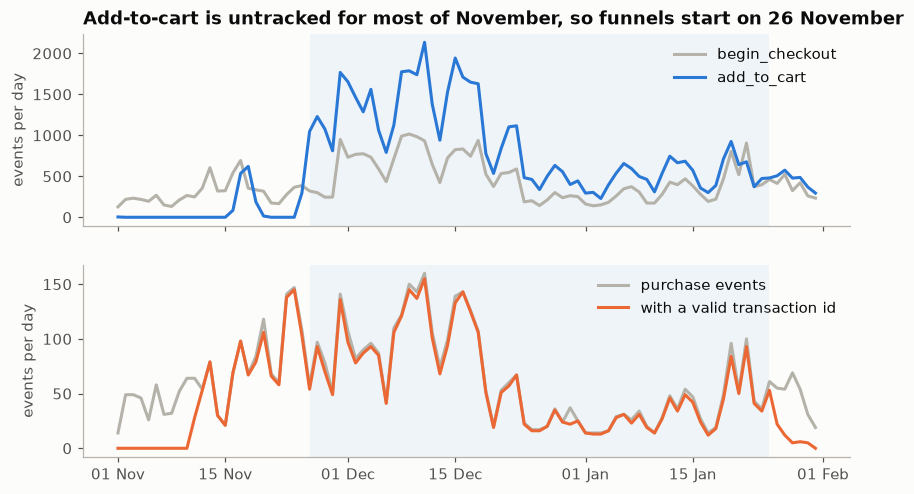

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
axes[0].plot(daily.event_date, daily.begin_checkout, color=a.GRAY, lw=2, label="begin_checkout")
axes[0].plot(daily.event_date, daily.add_to_cart, color=a.BLUE, lw=2, label="add_to_cart")
axes[0].set_ylabel("events per day")
axes[0].legend(frameon=False, loc="upper right")
axes[1].plot(daily.event_date, daily.purchase_events, color=a.GRAY, lw=2, label="purchase events")
axes[1].plot(daily.event_date, daily.purchases_with_valid_id, color=a.ORANGE, lw=2, label="with a valid transaction id")
axes[1].set_ylabel("events per day")
axes[1].legend(frameon=False, loc="upper right")
for ax in axes:
    ax.axvspan(pd.Timestamp("2020-11-26"), pd.Timestamp("2021-01-25"), color=a.BLUE, alpha=0.06, lw=0)
axes[1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
axes[0].set_title("Add-to-cart is untracked for most of November, so funnels start on 26 November")
fig.savefig("charts/tracking_gaps.png")

Windows used from here on (property dates):

| Window | Dates | Used for |
|---|---|---|
| Funnel window | 26 Nov 2020 – 25 Jan 2021 (61 days) | funnel, revenue at stake, segments, promotions, categories |
| Order window | 12 Nov 2020 – 25 Jan 2021 | weekly north star, channel revenue |
| Activation cohort | new users first seen 26 Nov – 26 Dec 2020 | activation and 30-day purchase (first-session add to cart is tracked and the 30-day window ends inside the order window) |

Totals for the full 92 days stay reported as model controls.

In [8]:
q("""
SELECT in_funnel_window, COUNT(*) AS sessions, SUM(orders) AS orders, SUM(revenue_usd) AS revenue_usd,
       AVG(has_order::INT) AS session_conversion, SUM(revenue_usd) / SUM(orders) AS aov
FROM fact_sessions GROUP BY 1 ORDER BY 1 DESC
""")

,in_funnel_window,sessions,orders,revenue_usd,session_conversion,aov
0,True,248669,"3,540.0000","245,147.0000",0.0129,69.2506
1,False,111460,911.0000,"62,493.0000",0.0075,68.5982


## Funnel order

The funnel counts whether a session has each event, not whether events happened in sequence. These are the sessions that reached a step without the previous one.

In [9]:
q("""
SELECT in_funnel_window,
       COUNT(*) FILTER (WHERE has_add_to_cart AND NOT has_view_item) AS cart_without_view,
       COUNT(*) FILTER (WHERE has_begin_checkout AND NOT has_add_to_cart) AS checkout_without_cart,
       COUNT(*) FILTER (WHERE has_begin_checkout AND NOT has_add_to_cart AND is_new_session) AS checkout_without_cart_new_session,
       COUNT(*) FILTER (WHERE has_add_payment_info AND NOT has_begin_checkout) AS payment_without_checkout,
       COUNT(*) FILTER (WHERE has_order AND NOT has_add_payment_info) AS order_without_payment,
       COUNT(*) FILTER (WHERE has_order AND NOT has_begin_checkout) AS order_without_checkout,
       COUNT(*) FILTER (WHERE has_purchase_event AND NOT has_order) AS purchase_event_without_order
FROM fact_sessions GROUP BY 1 ORDER BY 1 DESC
""")

,in_funnel_window,cart_without_view,checkout_without_cart,checkout_without_cart_new_session,payment_without_checkout,order_without_payment,order_without_checkout,purchase_event_without_order
0,True,10,1603,671,1,0,0,177
1,False,5,3542,2119,1,0,0,638


Most checkouts without a cart fall outside the funnel window, where `add_to_cart` was not tracked. Inside the window 1,603 remain, and no order lacks a checkout or payment step.

## Users

`traffic_source` and device vary across one user's events in the obfuscated sample, so `dim_users` takes each user's most frequent value (ties broken alphabetically) instead of an arbitrary one.

In [10]:
q("""
SELECT (SELECT COUNT(*) FROM dim_users) AS users,
       (SELECT COUNT(*) FROM dim_users WHERE is_new_user) AS new_users,
       (SELECT COUNT(*) FROM dim_users WHERE NOT is_new_user) AS first_seen_returning,
       (SELECT COUNT(*) FROM dim_users WHERE is_new_user AND in_activation_cohort) AS activation_cohort,
       (SELECT COUNT(*) FROM (SELECT user_pseudo_id FROM fact_events GROUP BY 1 HAVING COUNT(DISTINCT channel) > 1)) AS users_with_several_channels,
       (SELECT COUNT(*) FROM (SELECT user_pseudo_id FROM fact_events GROUP BY 1 HAVING COUNT(DISTINCT device_category) > 1)) AS users_with_several_devices,
       (SELECT COUNT(*) FROM (SELECT session_key FROM fact_events GROUP BY 1
            HAVING COUNT(DISTINCT channel) > 1 OR COUNT(DISTINCT device_category) > 1 OR COUNT(DISTINCT country) > 1)) AS inconsistent_sessions
""")

,users,new_users,first_seen_returning,activation_cohort,users_with_several_channels,users_with_several_devices,inconsistent_sessions
0,270154,260866,9288,99396,39900,4182,0


## Time zones

`event_date` (property date) equals the UTC date of `event_timestamp` for every event. A DuckDB connection left on the machine's local time zone would move events across dates, so every connection sets UTC.

In [11]:
tz = q("""
SELECT COUNT(*) FILTER (WHERE CAST(event_ts AS DATE) <> event_date) AS utc_date_differs,
       COUNT(*) FILTER (WHERE CAST(timezone('Asia/Kolkata', event_ts) AS DATE) <> event_date) AS ist_date_differs
FROM fact_events
""")
con.close()
tz

,utc_date_differs,ist_date_differs
0,0,993380
